***Maron Guimarães Activity for week 13***

In [1]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import numpy as np

In [2]:
# Load the Excel file
df = pd.read_excel("applications.xlsx")
# Preview the data
print(df.shape)
print(df.head())
# Check for missing values
print(df.isna().sum())

(17339, 7)
   Applicant Sex  SAT_ACT               College Admitted Enrolled  \
0          1   M     1460  Business & Economics      Yes       No   
1          2   F     1180        Math & Science       No       No   
2          3   M     1340        Arts & Letters      Yes       No   
3          4   M     1190  Business & Economics       No       No   
4          5   F     1290  Business & Economics       No       No   

   Extracurricular_Hours  
0                      5  
1                     10  
2                      7  
3                      1  
4                      4  
Applicant                0
Sex                      0
SAT_ACT                  0
College                  0
Admitted                 0
Enrolled                 0
Extracurricular_Hours    0
dtype: int64


College
Arts & Letters          6964
Business & Economics    4103
Math & Science          6272
Name: Applicant, dtype: int64


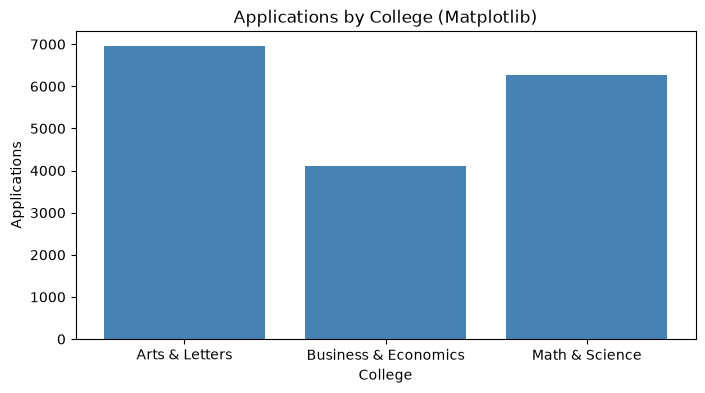

In [3]:
# Task 01
applications = df.groupby("College")["Applicant"].count()
print(applications)

#Matplotlib bar chart
plt.figure(figsize=(8, 4))
plt.bar(applications.index, applications.values, color="steelblue")
plt.title("Applications by College (Matplotlib)")
plt.xlabel("College")
plt.ylabel("Applications")
plt.show()


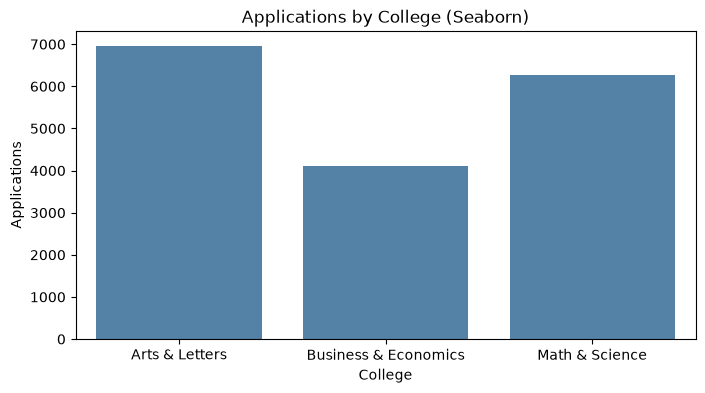

In [4]:
#Seaborn bar chart
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="College", order=applications.index, color="steelblue")
plt.title("Applications by College (Seaborn)")
plt.xlabel("College")
plt.ylabel("Applications")
plt.show()

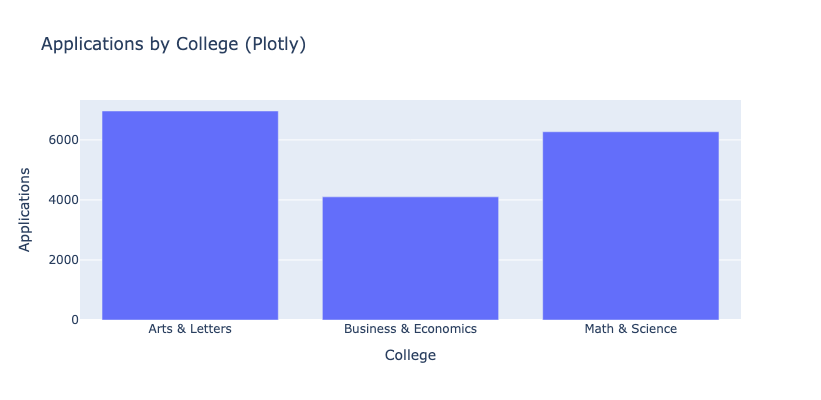

In [5]:
#Plotly bar chart
fig = px.bar(x=applications.index, y=applications.values,
             labels={"x": "College", "y": "Applications"},
             title="Applications by College (Plotly)", width=800, height=400)
fig.show()

In [6]:
# Distribution of scores
# Select  scores
scores = df["SAT_ACT"]
# Set 100-point bins
first_score = scores.min() // 100 * 100
last_score = scores.max() // 100 * 100 + 100
bins = list(range(first_score, last_score + 1, 100))

# Count scores 
for start in bins[:-1]:
    count = ((scores >= start) & (scores < start + 100)).sum()
    print(start, "to", start + 99, ":", count)


200 to 299 : 1
300 to 399 : 5
400 to 499 : 1
500 to 599 : 15
600 to 699 : 57
700 to 799 : 276
800 to 899 : 785
900 to 999 : 1705
1000 to 1099 : 2928
1100 to 1199 : 3910
1200 to 1299 : 3717
1300 to 1399 : 2363
1400 to 1499 : 1204
1500 to 1599 : 364
1600 to 1699 : 8


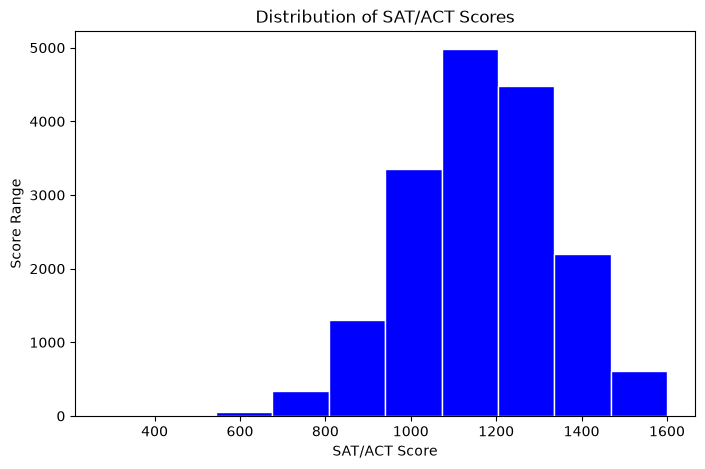

In [7]:
# Histogram - Matplotlib
# Figure size
plt.figure(figsize=(8, 5))
plt.hist(df['SAT_ACT'], bins=10, edgecolor='white', color = 'blue')
plt.title('Distribution of SAT/ACT Scores')
plt.xlabel('SAT/ACT Score')
plt.ylabel('Score Range')
plt.show()

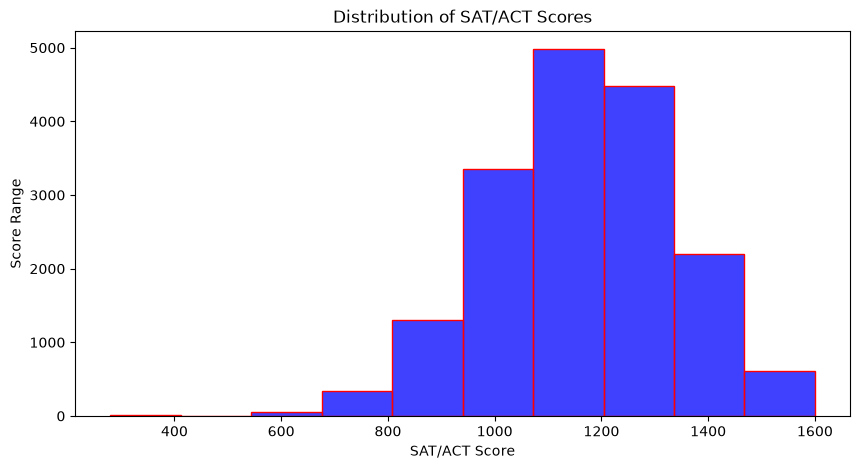

In [8]:
# Histogram- Seaborn
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='SAT_ACT', bins=10, edgecolor='red', color = 'blue')
plt.title('Distribution of SAT/ACT Scores')
plt.xlabel('SAT/ACT Score')
plt.ylabel('Score Range')
plt.show()


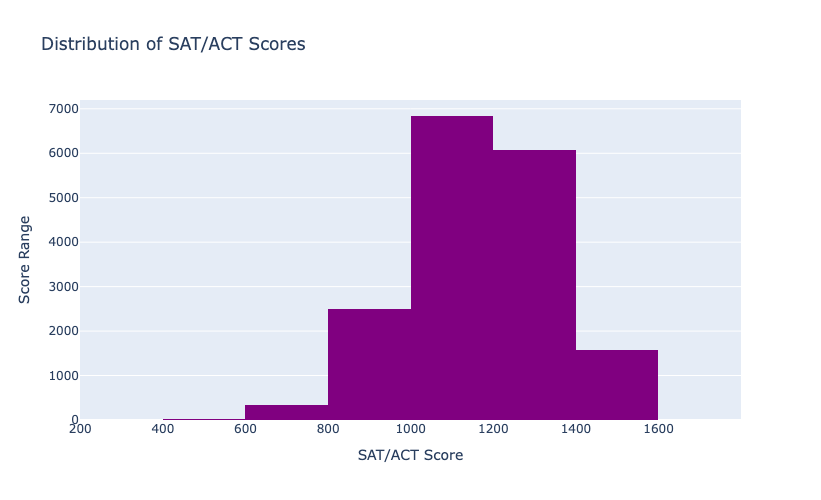

In [9]:
# Histogram - Plotly
fig = px.histogram(
    df,
    x='SAT_ACT',
    nbins=10,
    title='Distribution of SAT/ACT Scores',
    color_discrete_sequence=['purple'],
    width=800,
    height=500
)
fig.update_layout(
    xaxis_title='SAT/ACT Score',
    yaxis_title='Score Range'
)
fig.show()

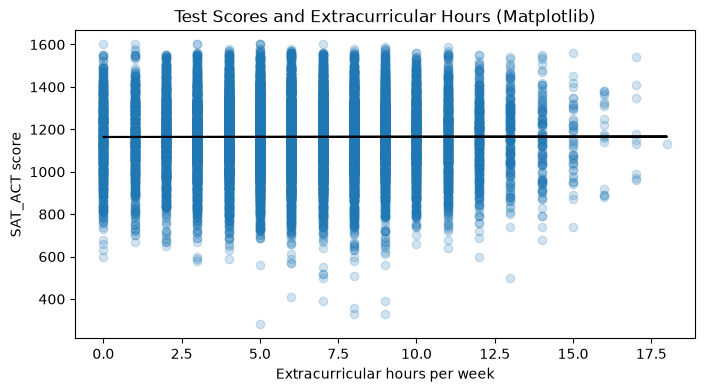

In [10]:
#Task 03 
#Matplotlib scatter plot
plt.figure(figsize=(8, 4))
plt.scatter(df["Extracurricular_Hours"], df["SAT_ACT"], alpha=0.2)
plt.title("Test Scores and Extracurricular Hours (Matplotlib)")
plt.xlabel("Extracurricular hours per week")
plt.ylabel("SAT_ACT score")
#Trendline 
m, b = np.polyfit(df['Extracurricular_Hours'], df['SAT_ACT'], 1)
plt.plot(df['Extracurricular_Hours'], m * df['Extracurricular_Hours'] + b, color='black')
plt.show()


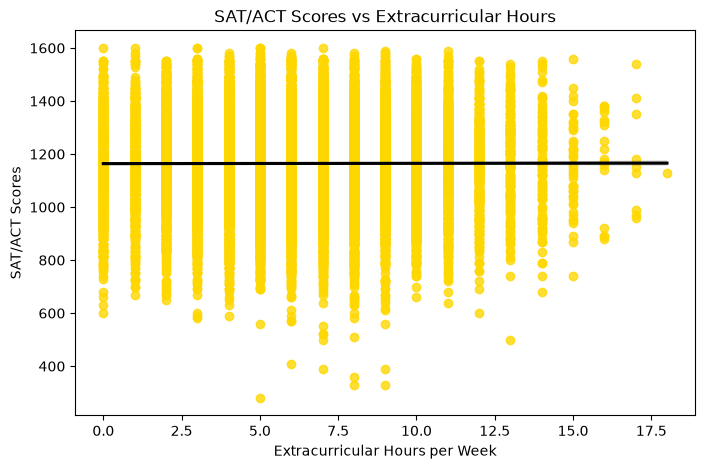

In [11]:
#Seaborn scatter plot
plt.figure(figsize=(8, 5))
sns.regplot(data=df,
    x='Extracurricular_Hours',
    y='SAT_ACT',
    scatter_kws={'color': 'gold'},
    line_kws={'color': 'black'},)
plt.title('SAT/ACT Scores vs Extracurricular Hours')
plt.xlabel('Extracurricular Hours per Week')
plt.ylabel('SAT/ACT Scores')
plt.show()

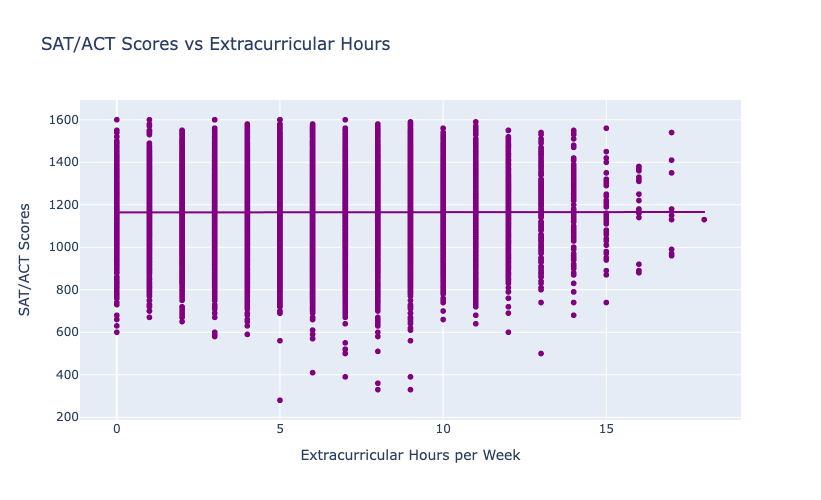

In [12]:
#Plotly scatter plot
fig = px.scatter(df,
    x='Extracurricular_Hours',
    y='SAT_ACT',
    trendline='ols',
    color_discrete_sequence=['purple'],
    title='SAT/ACT Scores vs Extracurricular Hours',
    width=800,
    height=500)
fig.update_layout(
    xaxis_title='Extracurricular Hours per Week',
    yaxis_title='SAT/ACT Scores')
fig.show()

 Findings and Recommendations

**Finding 1:** Arts & Letters has the highest number of applications but also has a lower admission rate than the other colleges. The university should review its admissions process and identify ways to attract qualified applicants who are more likely to enroll.

**Finding 2:** Business & Economics has a relatively strong enrollment rate among applicants. The university should continue promoting this college and explore ways to attract more prospective students.

**Finding 3:** The scatter plot shows little to no clear relationship between SAT_ACT scores and extracurricular hours. The university should evaluate academic performance and extracurricular involvement separately when making admissions decisions.